In [2]:
import numpy as np
import struct
import matplotlib.pyplot as plt


def _get_field(wav, offset, lent):
    wav.seek(0)
    wav.seek(offset, 0)
    return int.from_bytes(wav.read(lent), byteorder='little')

def _go_to_wav_data(fin):
    fin_header_size = _get_field(fin, 16, 4)
    fin_bit_rate = _get_field(fin, 34, 2)
    if fin_header_size == 16:
        fin.seek(44)
    elif fin_header_size == 18:
        fin.seek(46)
    else:
        print('Unknown wav format\n')
        fin.seek(0)
        fin_bit_rate = 32
    return fin_bit_rate


def read_signed_integer(fin, num_bytes):
    # Read the specified number of bytes from the file
    data = fin.read(num_bytes)
    # Check the sign bit in the last byte
    if not data:
        return None
    if data[-1] & 0x80:
        # If negative, pad with 1s in the remaining bytes
        pad_value = (2 ** (8 * (4 - num_bytes)) - 1).to_bytes(4 - num_bytes, 'big', signed=False)
        data += pad_value
    else:
        # If positive, pad with 0s in the remaining bytes
        pad_value = b'\x00' * (4 - num_bytes)
        data += pad_value
    # Unpack the 4-byte chunk as a signed 32-bit integer
    value, = struct.unpack("i", data)
    return value


def get_data(infile):
    data_list = []
    with open(infile, "rb") as fin:
        fin_bit_rate = int(_go_to_wav_data(fin)/8)
        while True:
            value = read_signed_integer(fin, fin_bit_rate)
            if value is None:  # Break the loop if there is no more data to read
                break
            data_list.append(value)
    return data_list

In [4]:
input_file = "../BUILD/CMAKE_denoiser_dsp_test_gvsoc/output_p232_334.wav"
golden_file = "./utils/output_p232_334.wav"

input_data = np.array(get_data(input_file))
section = input_data[2000:3000]

noise = 100000 * np.random.randn(len(input_data))
signal_long = (input_data + noise)

correlation = np.correlate(signal_long, section, mode='valid')

index_max_correlation = np.argmax(correlation)

noisy_section = signal_long[index_max_correlation:index_max_correlation + len(section)]
def db_diff(checking_section, most_correspondig_ref_section):
    return 20 * np.log10(np.abs(checking_section/most_correspondig_ref_section))

In [6]:
in_signal = np.array(get_data(input_file))
ref_signal = np.array(get_data(golden_file))
checking_section = in_signal[10:-10] # takes central part of the file

correlation = np.correlate(ref_signal, checking_section, mode='valid')
index_max_correlation = np.argmax(correlation)
most_correspondig_ref_section = ref_signal[index_max_correlation:index_max_correlation + len(checking_section)]
db_difference = 20 * np.log10(np.abs(checking_section/most_correspondig_ref_section))

np.mean(np.abs(db_difference))

FileNotFoundError: [Errno 2] No such file or directory: './utils/output_p232_334.wav'

In [101]:
val = np.argmax(db_difference)
print(most_correspondig_ref_section[val-10:val+10])
print(checking_section[val-10:val+10])
print(db_diff(checking_section[val-10:val+10], most_correspondig_ref_section[val-10:val+10]))

[-795419 -737213 -673220 -603836 -529329 -450018 -366353 -278854 -188096
  -94875    -575   92501  181170  261942  331945  389769  435767  471642
  499542  521159]
[-799384 -737070 -670990 -600402 -524091 -441360 -352675 -259649 -164497
  -69402   23811  113577  198275  276046  344965  403508  451056  488091
  516005  536590]
[ 4.31898151e-02 -1.68499836e-03 -2.88192346e-02 -4.95374268e-02
 -8.63797249e-02 -1.68738285e-01 -3.30501545e-01 -6.19804485e-01
 -1.16443156e+00 -2.71559606e+00  3.23421958e+01  1.78287931e+00
  7.83633484e-01  4.55526386e-01  3.34178052e-01  3.00897093e-01
  2.99522511e-01  2.97766547e-01  2.81638032e-01  2.53446655e-01]


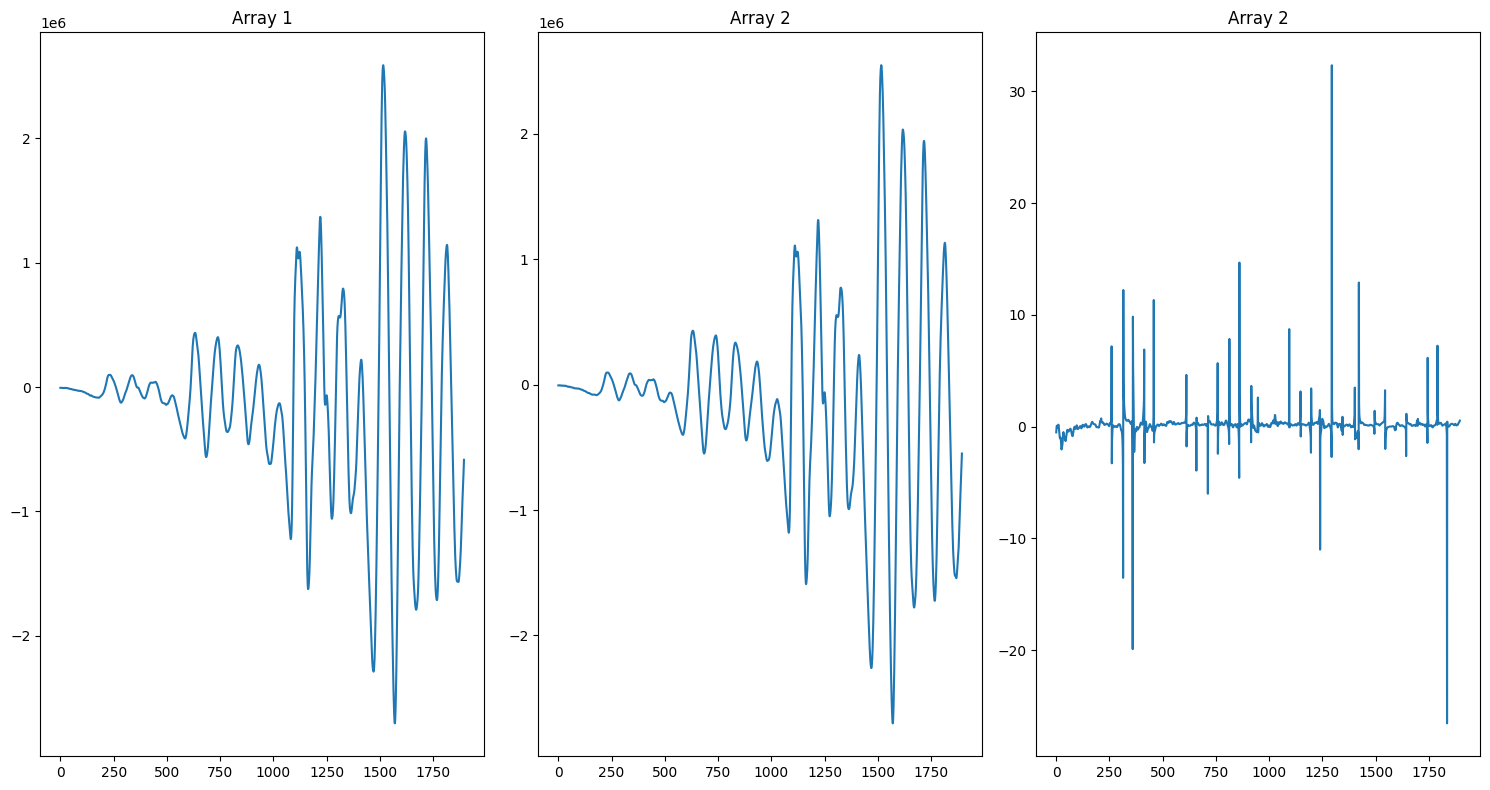

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))
# Plot the first array on the first subplot
plt.subplot(1, 3, 1)
plt.plot(checking_section, label='Array 1')
plt.title('Array 1')
# Plot the second array on the second subplot
plt.subplot(1, 3, 2)
plt.plot(most_correspondig_ref_section, label='Array 2')
plt.title('Array 2')
plt.subplot(1, 3, 3)
plt.plot(20 * np.log10(np.abs(checking_section/most_correspondig_ref_section)), label='Array 2')
plt.title('Array 2')
# Show the plo
plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

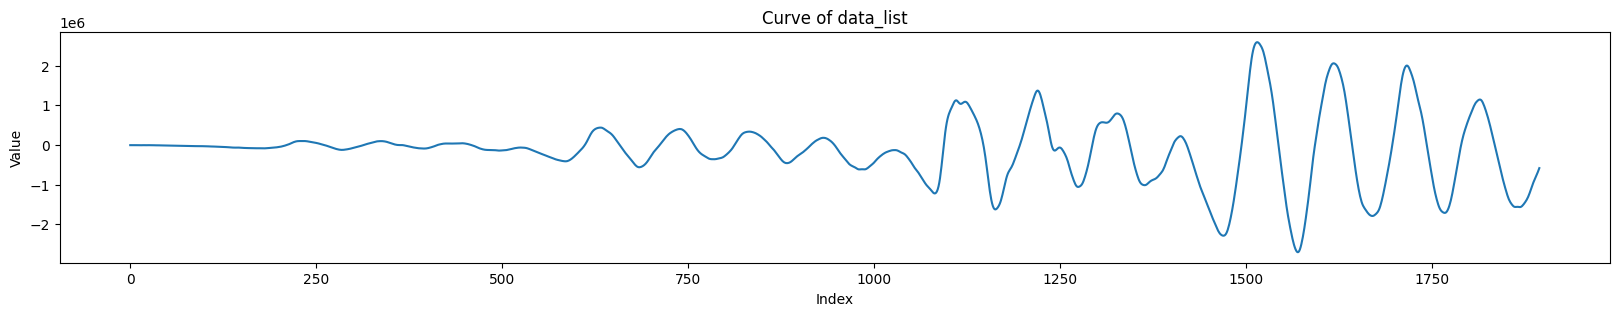

In [84]:

plt.figure(figsize=(20, 3))
plt.plot(checking_section)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Curve of data_list')
plt.show()

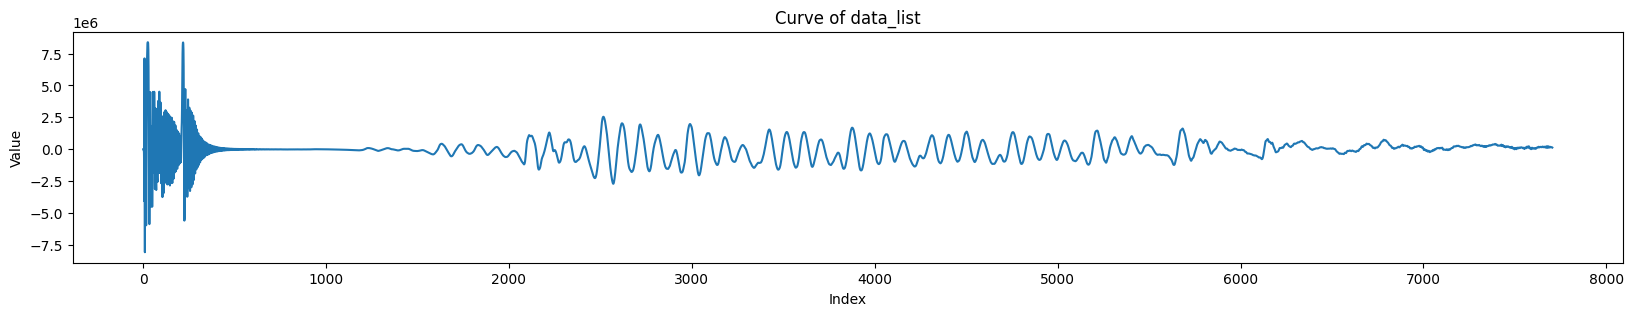

In [85]:

plt.figure(figsize=(20, 3))
plt.plot(ref_signal)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Curve of data_list')
plt.show()

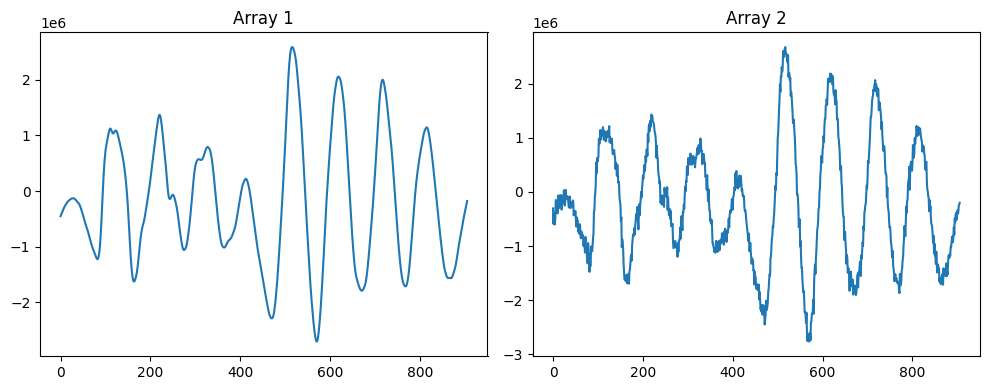

79762.47131720824
8.338338169022224


In [86]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
# Plot the first array on the first subplot
plt.subplot(1, 2, 1)
plt.plot(section, label='Array 1')
plt.title('Array 1')
# Plot the second array on the second subplot
plt.subplot(1, 2, 2)
plt.plot(noisy_section, label='Array 2')
plt.title('Array 2')
# Show the plo
plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()

mse = np.mean(np.abs(section - noisy_section))
print(mse)
print(mse / np.mean(np.abs(section)) * 100)

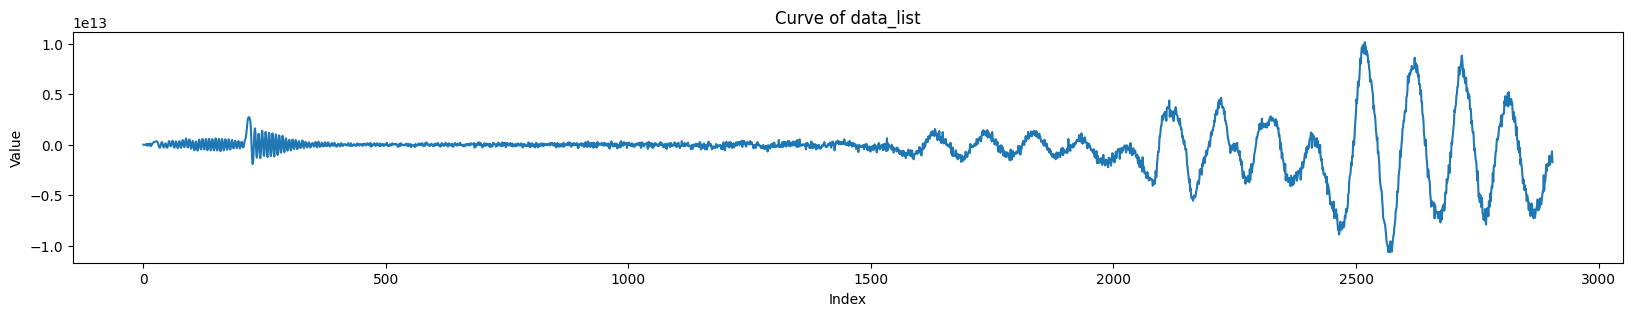

In [63]:

plt.figure(figsize=(20, 3))
plt.plot(signal_long)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Curve of data_list')
plt.show()

In [14]:
100000/2**24 * 100

0.5960464477539062

In [19]:
#!/usr/bin/env python3

import argparse
import struct
import numpy as np
from scipy.signal import argrelextrema

infile = "../output_p232_334.wav"
reffile = "../utils/golden.wav"
def _get_field(wav, offset, lent):
    wav.seek(0)
    wav.seek(offset, 0)
    return int.from_bytes(wav.read(lent), byteorder='little')

def _get_spec(fin):
    fin_header_size = _get_field(fin, 16, 4)
    sample_rate = _get_field(fin, 24, 4)
    fin_bit_rate = _get_field(fin, 34, 2)
    num_channels = _get_field(fin, 22, 2)
    if fin_header_size == 16:
        fin.seek(44)
    elif fin_header_size == 18:
        fin.seek(46)
    else:
        print('Unknown wav format\n')
        fin.seek(0)
        fin_bit_rate = 32
    return fin_bit_rate, sample_rate, num_channels


def _read_signed_integer(fin, num_bytes):
    # Read the specified number of bytes from the file
    data = fin.read(num_bytes)
    # Check the sign bit in the last byte
    if not data:
        return None
    if data[-1] & 0x80:
        # If negative, pad with 1s in the remaining bytes
        pad_value = (2 ** (8 * (4 - num_bytes)) - 1).to_bytes(4 - num_bytes, 'big', signed=False)
        data += pad_value
    else:
        # If positive, pad with 0s in the remaining bytes
        pad_value = b'\x00' * (4 - num_bytes)
        data += pad_value
    # Unpack the 4-byte chunk as a signed 32-bit integer
    value, = struct.unpack("i", data)
    return value


def get_data(infile):
    data_list = []
    with open(infile, "rb") as fin:
        fin_bit_rate, sample_rate, num_channels = _get_spec(fin)
        while True:
            value = _read_signed_integer(fin, int(fin_bit_rate/8))
            if value is None:  # Break the loop if there is no more data to read
                break
            data_list.append(value)
    return np.array(data_list).reshape(-1, num_channels).T, [fin_bit_rate, sample_rate, num_channels]


def mse_idx_correl(i, ref_signal, checking_section):
    most_correspondig_ref_section = ref_signal[i:i + len(checking_section)]
    return np.mean((most_correspondig_ref_section - checking_section)**2)

def find_corresponding_section(ref_signal, checking_section):
    correlation = np.correlate(ref_signal, checking_section, mode='valid')
    p = list(argrelextrema(correlation, np.greater)[0])
    index_max_correl = p[np.argmin([mse_idx_correl(i, ref_signal, checking_section) for i in p])]
    
    most_correspondig_ref_section = ref_signal[index_max_correl:index_max_correl + len(checking_section)]
    return most_correspondig_ref_section


# get data from both file
in_signal, fin_specs = get_data(infile)
ref_signal, ref_specs = get_data(reffile)
if fin_specs != ref_specs:
    print("Files have differents properties")
    exit(-1)


for i in range(fin_specs[2]):
     # select part of file used to check
    checking_section = in_signal[i, int(fin_specs[1] * 150 / 1000) :]
    most_correspondig_ref_section = find_corresponding_section(ref_signal[i, :], checking_section)
    print(np.max(np.abs(most_correspondig_ref_section - checking_section)))
    print(np.argmax(np.abs(most_correspondig_ref_section - checking_section)))
    if np.max(np.abs(most_correspondig_ref_section - checking_section)) > 10000000:
        print("Files don't match")
        exit(-1)

2159978
3


In [2]:
fin_specs[1]

48000

In [108]:
checking_section = in_signal[i, int(fin_specs[1] * 100 / 1000) :]
ref_signal = ref_signal[i, 0:15000]
correlation = np.correlate(ref_signal, checking_section, mode = 'valid')
index_max_correlation = np.argmax(correlation)
ref_signal[index_max_correlation:index_max_correlation + len(checking_section)]
print(index_max_correlation)

0


In [39]:
len(ref_signal)- len(checking_section)

5442

In [18]:
10000000 * 100 / 2**32

0.23283064365386963

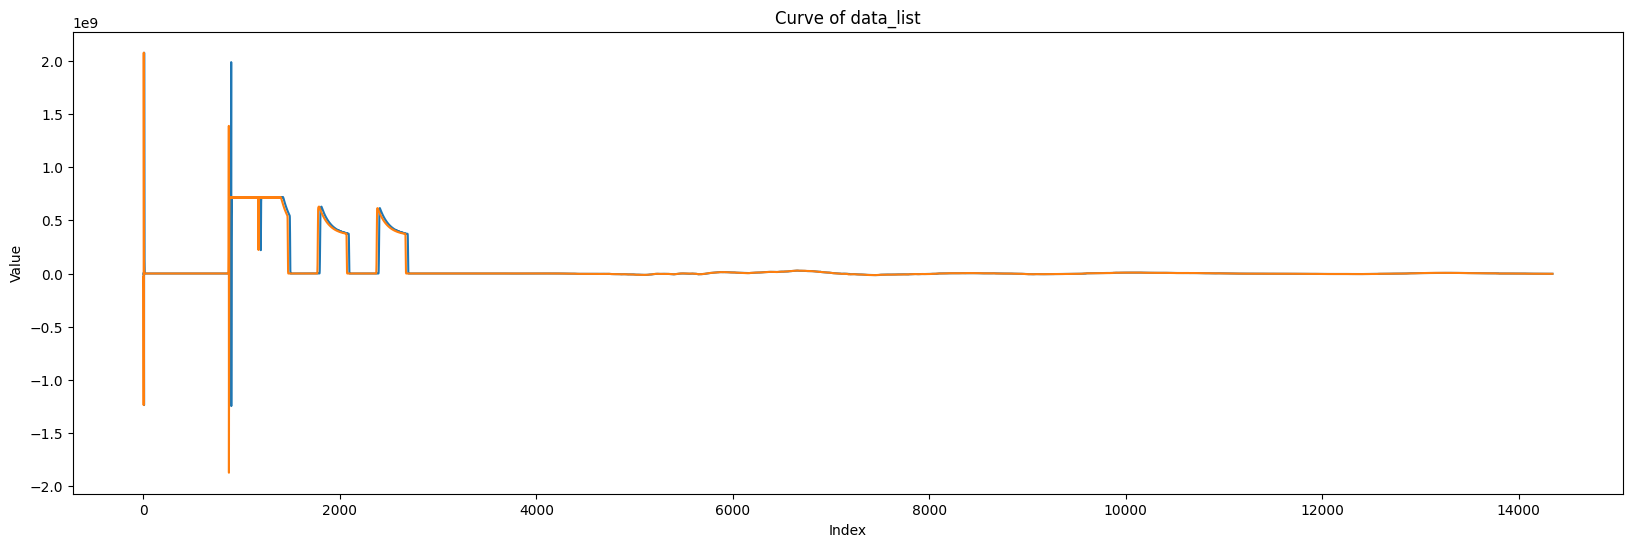

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 6))
plt.plot(checking_section)
plt.plot(most_correspondig_ref_section)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Curve of data_list')
plt.show()

In [75]:
import numpy as np

A = np.array([100, 2, 3, 4, 5, 6, 7, 8, 9, 10])
B = np.array([4, 5, 6])

# Inverser la séquence B
B_inverse = np.flip(B)

# Calculer la convolution entre A et B_inverse
convolution_result = np.convolve(A, B_inverse, mode='valid')

# Trouver l'indice où la convolution est maximale
max_index = np.argmax(convolution_result)

# La position de B dans A est donnée par l'indice où la convolution est maximale
position_of_B_in_A = max_index

print("La position de B dans A est à l'indice:", position_of_B_in_A)


La position de B dans A est à l'indice: 0


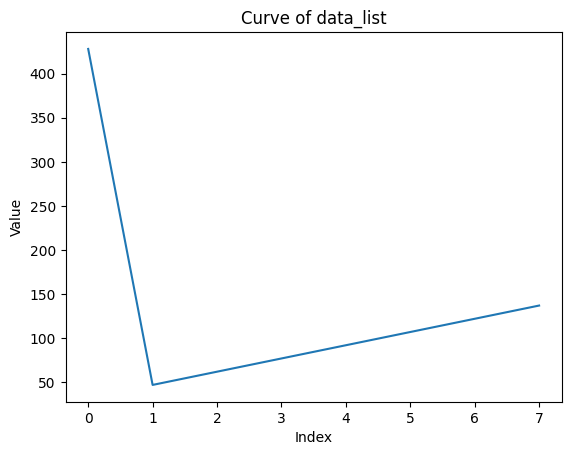

In [76]:
plt.plot(convolution_result)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Curve of data_list')
plt.show()

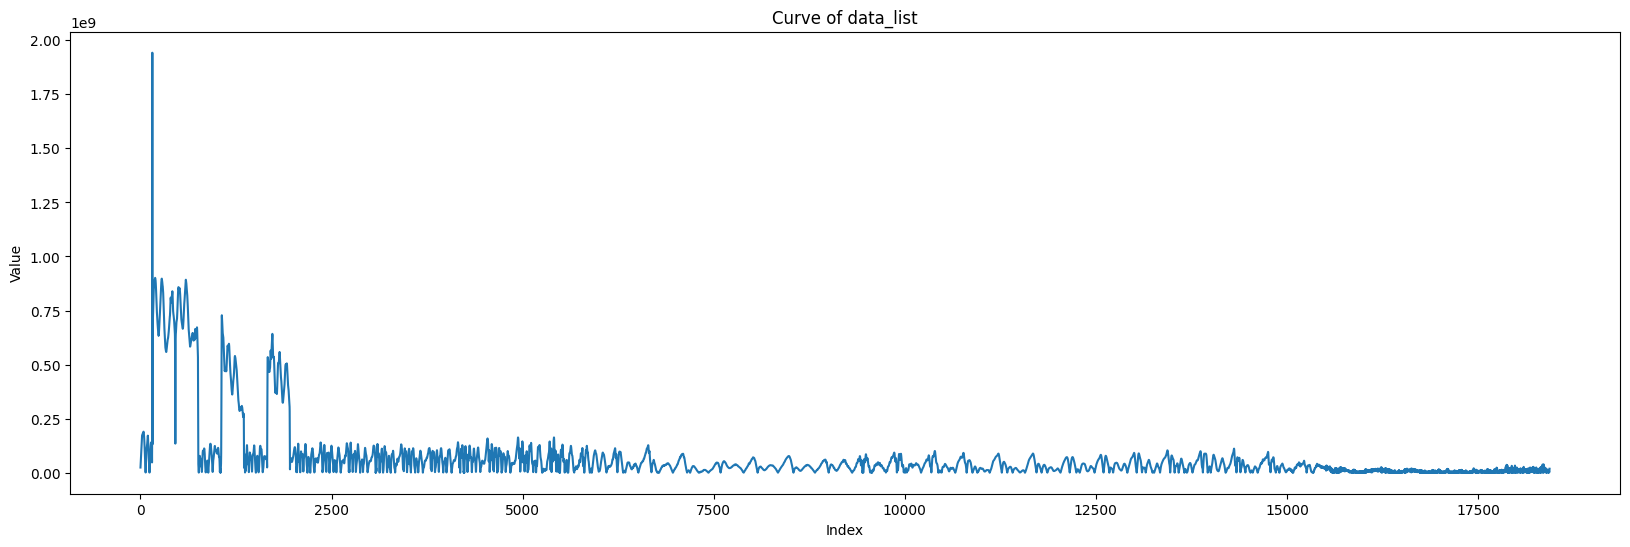

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 6))
plt.plot(np.abs(most_correspondig_ref_section - checking_section))
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Curve of data_list')
plt.show()

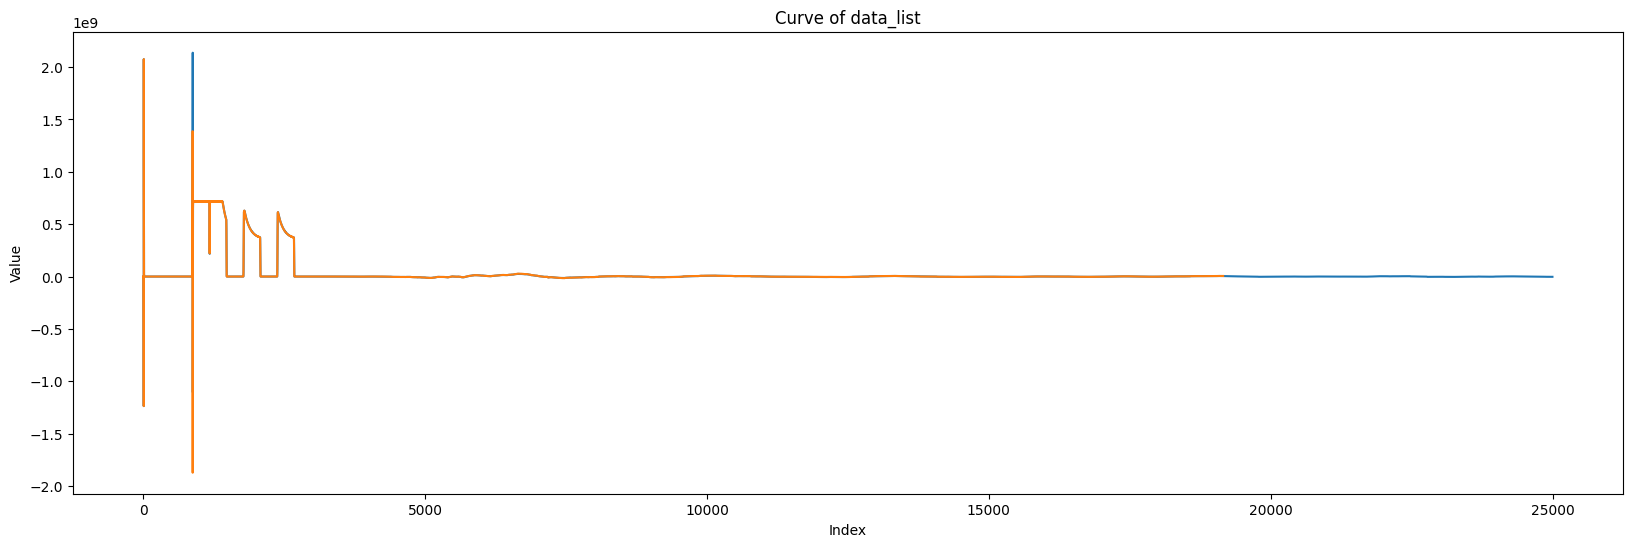

In [15]:
plt.figure(figsize=(20, 6))
plt.plot(ref_signal[0, 0:25000])
plt.plot(in_signal[0, :])
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Curve of data_list')
plt.show()

/tmp/ipykernel_4805/714017334.py:1: RuntimeWarning: divide by zero encountered in log10
  20 * np.log10(0)


-inf

gapy command :

/home/thibaut/workspace/gap_sdk/utils/gapy_v2/bin/gapy --target=gap9.evk --target-dir=/home/thibaut/workspace/gap_sdk/gvsoc/gvsoc_gap --target-dir=/home/thibaut/workspace/gap_sdk/gvsoc/gvsoc/models --model-dir=/home/thibaut/workspace/gap_sdk/install/workstation/models --platform=gvsoc --work-dir=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build --target-property=boot.flash_device=mram --target-property=boot.mode=flash --multi-flash-content=/home/thibaut/workspace/gap_sdk/utils/layouts/default_layout_multi.json --flash-property=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build/telephony@mram:app:binary image --binary=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build/telephony --config-opt=**/gvsoc/proxy/enabled=true --config-opt=**/gvsoc/proxy/port=30000 --target-opt=addon_testbench_enabled=true --flash-property=/home/thibaut/workspace/gap_sdk/install/target/bin/fsbl@mram:fsbl:binary --flash-property=/home/thibaut/workspace/gap_sdk/install/target/bin/ssbl@mram:ssbl:binary


/home/thibaut/workspace/gap_sdk/utils/gapy_v2/bin/gapy --target=gap9.evk --target-dir=/home/thibaut/workspace/gap_sdk/gvsoc/gvsoc_gap --target-dir=/home/thibaut/workspace/gap_sdk/gvsoc/gvsoc/models --model-dir=/home/thibaut/workspace/gap_sdk/install/workstation/models --platform=gvsoc --work-dir=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build --target-property=boot.flash_device=mram --target-property=boot.mode=flash --multi-flash-content=/home/thibaut/workspace/gap_sdk/utils/layouts/default_layout_multi.json --flash-property=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build/telephony@mram:app:binary flash --binary=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build/telephony --config-opt=**/gvsoc/proxy/enabled=true --config-opt=**/gvsoc/proxy/port=30000 --target-opt=addon_testbench_enabled=true --flash-property=/home/thibaut/workspace/gap_sdk/install/target/bin/fsbl@mram:fsbl:binary --flash-property=/home/thibaut/workspace/gap_sdk/install/target/bin/ssbl@mram:ssbl:binary


/home/thibaut/workspace/gap_sdk/utils/gapy_v2/bin/gapy --target=gap9.evk --target-dir=/home/thibaut/workspace/gap_sdk/gvsoc/gvsoc_gap --target-dir=/home/thibaut/workspace/gap_sdk/gvsoc/gvsoc/models --model-dir=/home/thibaut/workspace/gap_sdk/install/workstation/models --platform=gvsoc --work-dir=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build --target-property=boot.flash_device=mram --target-property=boot.mode=flash --multi-flash-content=/home/thibaut/workspace/gap_sdk/utils/layouts/default_layout_multi.json --flash-property=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build/telephony@mram:app:binary run --binary=/home/thibaut/workspace/gap_sdk/examples/gap9/basic/interfaces/sai/telephony/build/telephony --config-opt=**/gvsoc/proxy/enabled=true --config-opt=**/gvsoc/proxy/port=30000 --target-opt=addon_testbench_enabled=true --flash-property=/home/thibaut/workspace/gap_sdk/install/target/bin/fsbl@mram:fsbl:binary --flash-property=/home/thibaut/workspace/gap_sdk/install/target/bin/ssbl@mram:ssbl:binary



In [9]:
import sys
import numpy as np

def charger_timestamps(fichier_entree):
    # Initialiser une liste pour stocker les timestamps
    timestamps = []
    lignes = []

    # Ouvrir le fichier d'entrée en lecture
    with open(fichier_entree, 'r') as entree:
        # Parcourir chaque ligne du fichier d'entrée
        for ligne in entree:
            # Séparer la ligne en utilisant ':' comme séparateur
            parties = ligne.split(':')
            # Convertir le premier nombre en timestamp et l'ajouter à la liste
            try:
                timestamps.append(int(parties[0].strip()))
                lignes.append(str(ligne))
            except:
                print(str(ligne))

    # Convertir la liste de timestamps en un tableau NumPy
    timestamps_array = np.array(timestamps)

    return timestamps_array, lignes

# Vérifier si le nom du fichier a été fourni en ligne de commande
if len(sys.argv) != 2:
    print("Utilisation: python script.py fichier_entree.txt")
else:
    # Récupérer le nom du fichier à partir des arguments de la ligne de commande
    fichier_entree = "../traceRAM-1.txt"

    # Appeler la fonction pour charger les timestamps dans un tableau NumPy
    timestamps_array, lines = charger_timestamps(fichier_entree)

Opened proxy on socket 30000



KeyboardInterrupt: 

In [36]:
with open("../isn_ram_trace.txt", 'r') as entree:
    file = entree.readlines()
timestamps_fc = [
    int(ligne.split(':')[0].strip()) 
    for ligne in file 
    if "/chip/soc/fc/insn" in ligne]
timestamps_mram = np.array([
    int(ligne.split(':')[0].strip()) 
    for ligne in file 
    if "Opened proxy on socket 30000" not in ligne and "After 5ms run" not in ligne and "/chip/soc/fc/insn" not in ligne
])
ligne_mram = [ligne
    for ligne in file 
    if "Opened proxy on socket 30000" not in ligne and "After 5ms run" not in ligne and "/chip/soc/fc/insn" not in ligne
]
ful_lines = [ligne
    for ligne in file 
    if "Opened proxy on socket 30000" not in ligne and "After 5ms run" not in ligne
]

In [37]:
np.argmax(np.diff(timestamps_mram))

8409

In [ ]:
ligne_mram[9127-20 : 9127+10]

In [31]:
indices = [index for index, string in enumerate(ful_lines) if "/chip/soc/udma/mram0/TX_DEST/trace" in string]
print(indices)

[2623, 3935, 311927, 319102, 339040, 354151, 361614, 2512208]


In [34]:
print(ful_lines[311927])

9923936696: 509721: [/chip/soc/udma/mram0/TX_DEST/trace                                   ] Register access (name: mram0/TX_DEST, offset: 0x4, size: 0x4, is_write: 0x1, value: { DEST=0x2 })



In [13]:
lines[9127-20 : 9127+10]

['561963280: 19753: [\x1b/chip/soc/udma/mram0/dc_fifo                                         \x1b[0m] Stalling fifo\n',
 '561969376: 19754: [\x1b/chip/soc/udma/mram0/dc_fifo                                         \x1b[0m] Receiver FSM handler\n',
 '561987664: 19755: [\x1b/chip/soc/udma/mram0/dc_fifo                                         \x1b[0m] Popping data from DC fifo (data: 0x7ff996b9e990, size: 16, nb_elems: 1)\n',
 '562693968: 92319: [\x1b/chip/soc/mram/active/trace                                          \x1b[0m] Release register\n',
 '562693968: 19794: [\x1b/chip/soc/udma/mram0/active/trace                                    \x1b[0m] Release register\n',
 '566653040: 20012: [\x1b/chip/soc/udma/mram0/active/trace                                    \x1b[0m] Release register\n',
 '2061541632: 102310: [\x1b/chip/soc/udma/mram0/RX_DEST/trace                                   \x1b[0m] Modified register (value: 0x0)\n',
 '2061541632: 102310: [\x1b/chip/soc/udma/mram0/RX_DEST/trac